✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.

PART 1: PART OF SPEECH TAGGING

Sentence: The cat is sitting on the mat.
------------------------------------------------------------
WORD            POS             TAG            
The             DET             DT             
cat             NOUN            NN             
is              AUX             VBZ            
sitting         VERB            VBG            
on              ADP             IN             
the             DET             DT             
mat             NOUN            NN             
.               PUNCT           .              

Sentence: John plays football every evening.
---------------------------------------------------

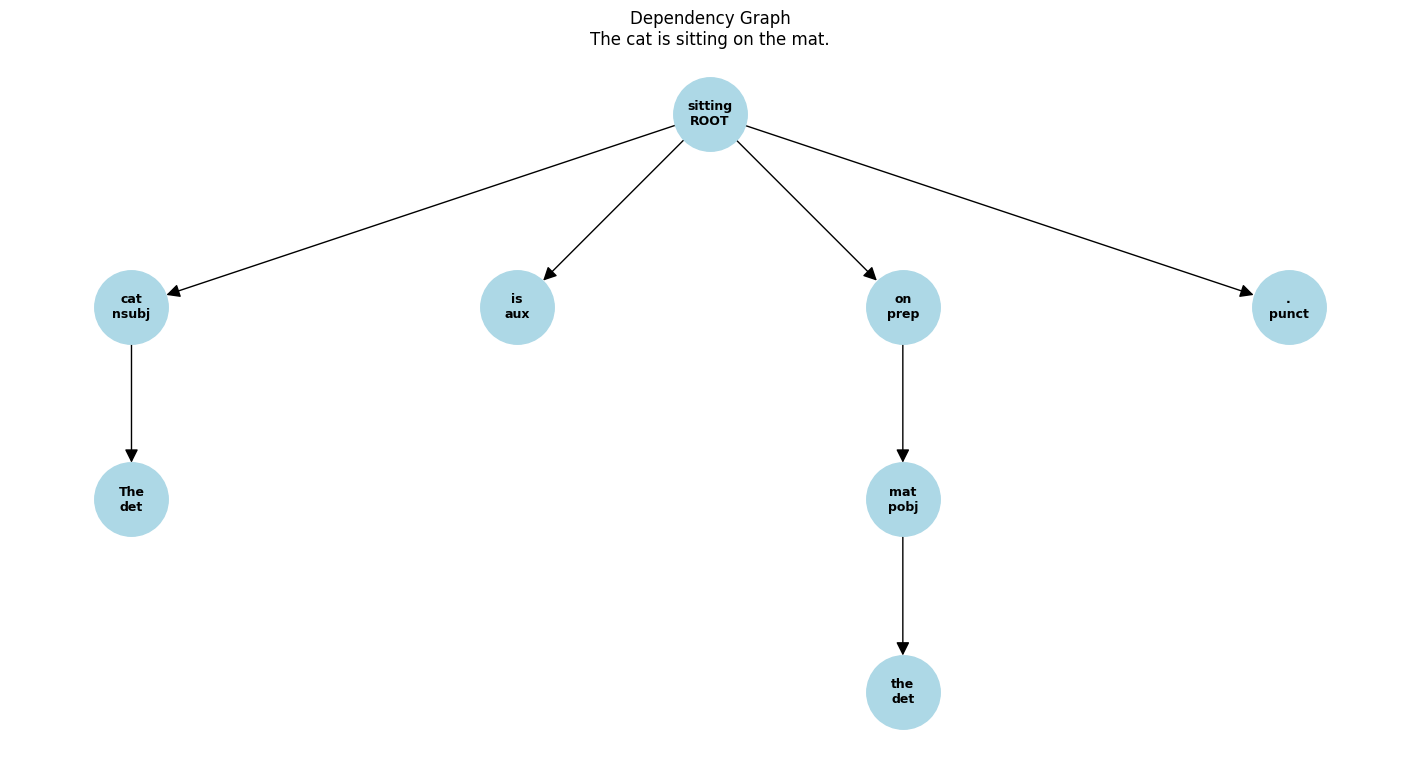


Dependency Relationships:
The --> det --> cat
cat --> nsubj --> sitting
is --> aux --> sitting
sitting --> ROOT --> sitting
on --> prep --> sitting
the --> det --> mat
mat --> pobj --> on
. --> punct --> sitting

Sentence: John plays football every evening.


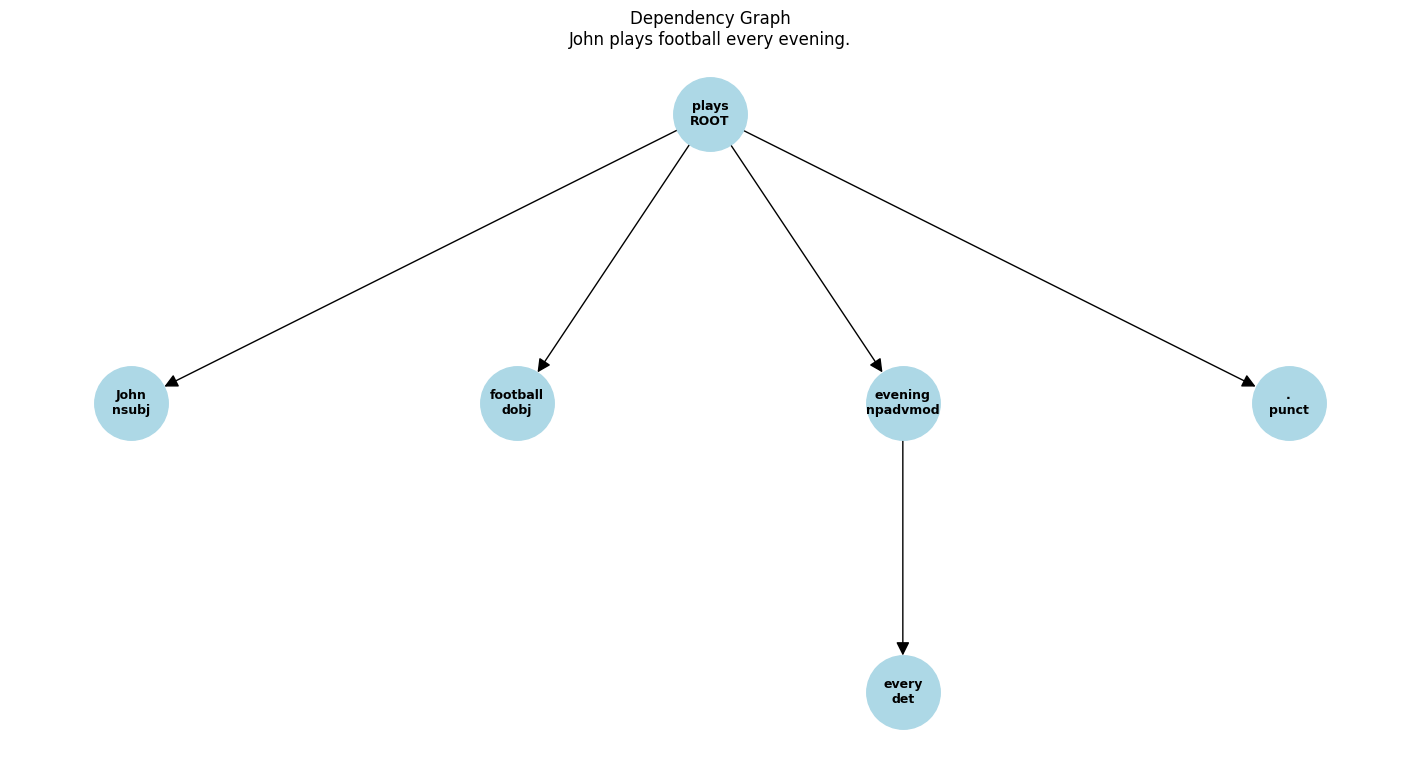


Dependency Relationships:
John --> nsubj --> plays
plays --> ROOT --> plays
football --> dobj --> plays
every --> det --> evening
evening --> npadvmod --> plays
. --> punct --> plays

Sentence: The students are reading books in the library.


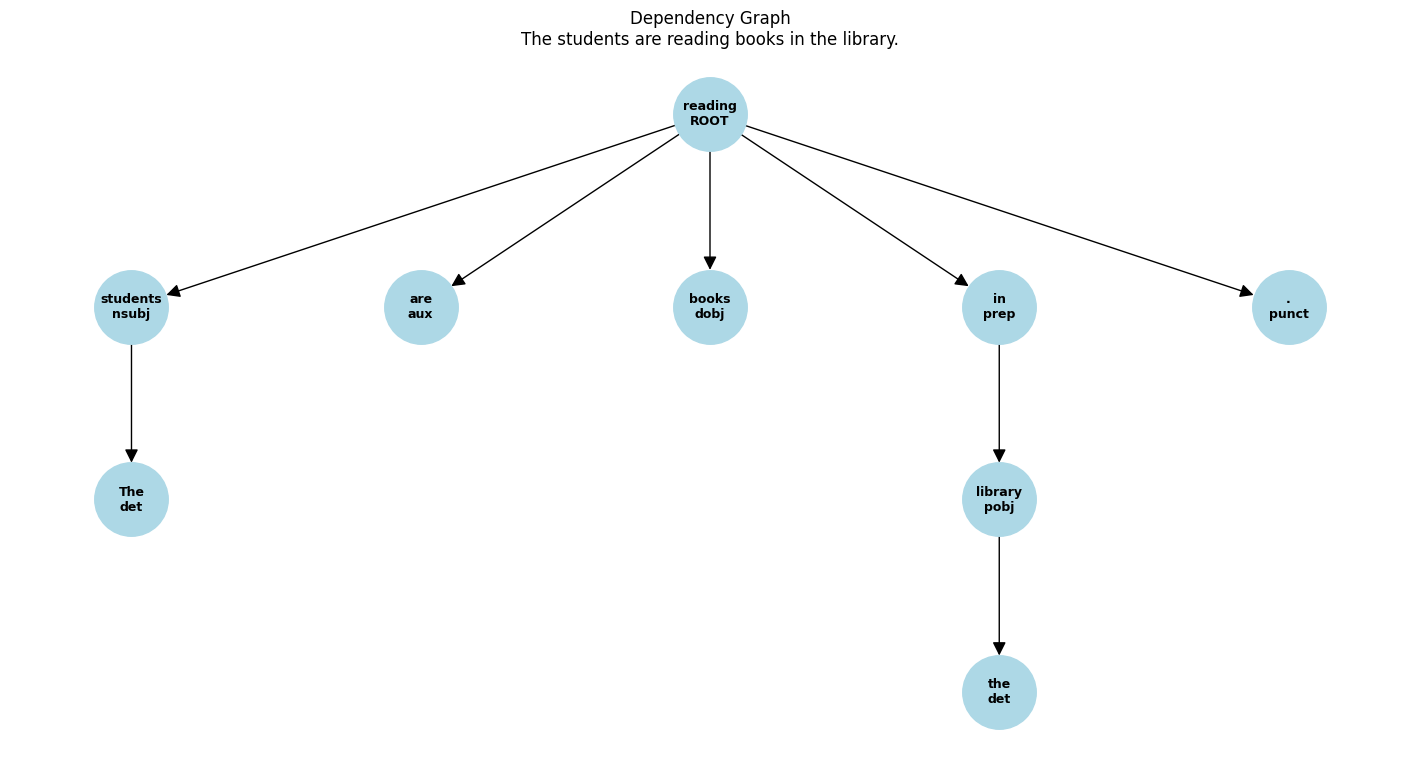


Dependency Relationships:
The --> det --> students
students --> nsubj --> reading
are --> aux --> reading
reading --> ROOT --> reading
books --> dobj --> reading
in --> prep --> reading
the --> det --> library
library --> pobj --> in
. --> punct --> reading

Sentence: She is eating a delicious apple.


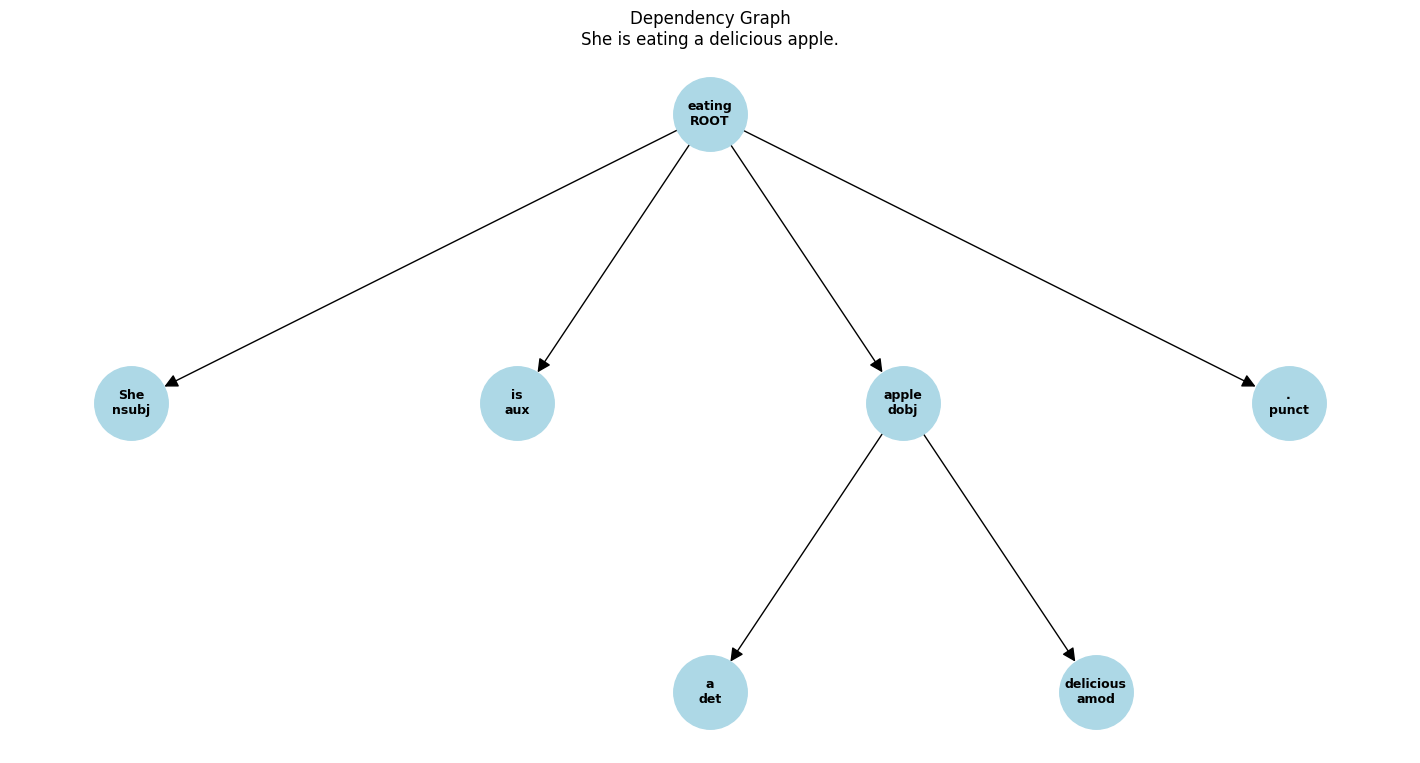


Dependency Relationships:
She --> nsubj --> eating
is --> aux --> eating
eating --> ROOT --> eating
a --> det --> apple
delicious --> amod --> apple
apple --> dobj --> eating
. --> punct --> eating

Sentence: The teacher explains the lesson clearly.


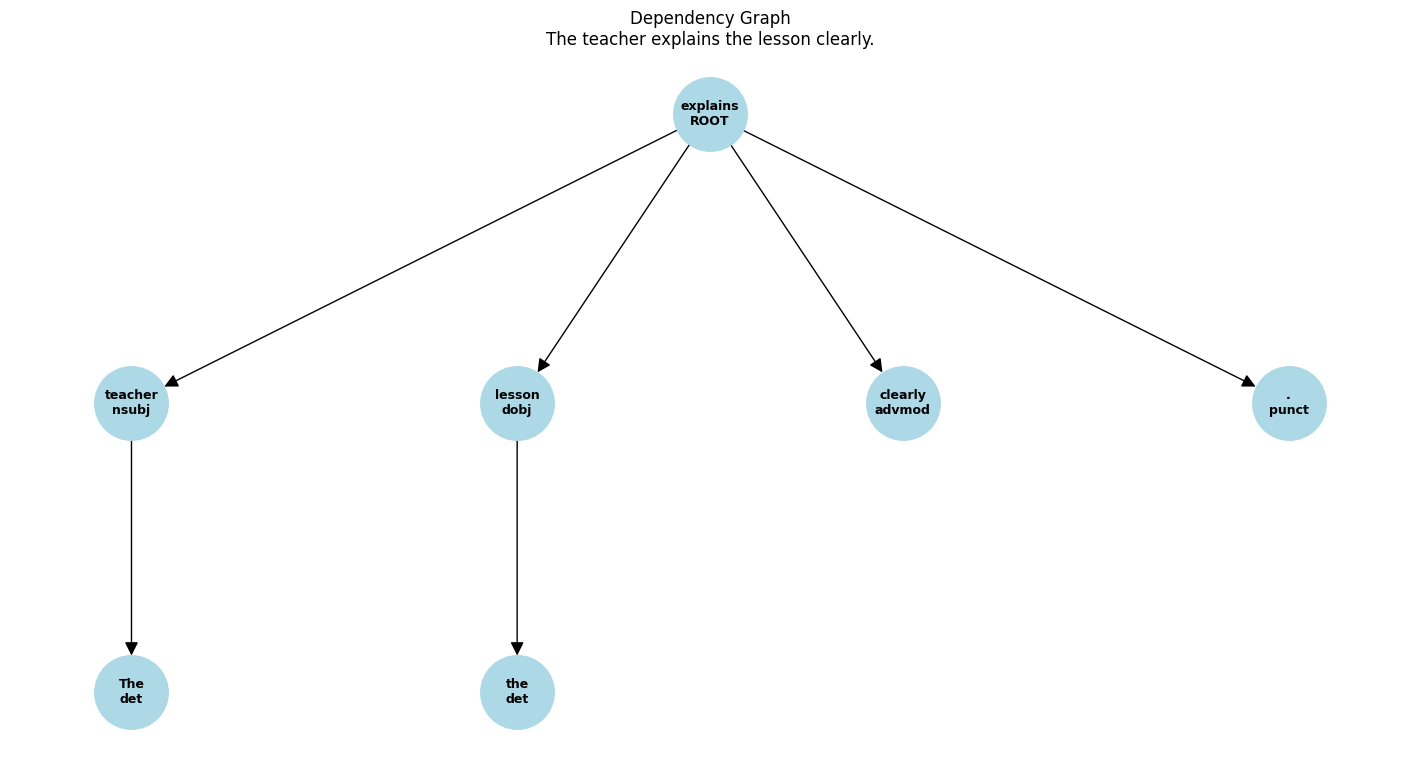


Dependency Relationships:
The --> det --> teacher
teacher --> nsubj --> explains
explains --> ROOT --> explains
the --> det --> lesson
lesson --> dobj --> explains
clearly --> advmod --> explains
. --> punct --> explains

PART 3: PHRASE STRUCTURE TREE

Sentence: The cat is sitting on the mat.

POS Tagged Words:
[('The', 'DT'), ('cat', 'NN'), ('is', 'VBZ'), ('sitting', 'VBG'), ('on', 'IN'), ('the', 'DT'), ('mat', 'NN')]

Phrase Structure Tree:
                              S                             
         _____________________|________                      
        |                              VP                   
        |            __________________|_____                
        |           |         |              PP             
        |           |         |         _____|_____          
        NP          |         |        |           NP       
   _____|____       |         |        |      _____|____     
The/DT     cat/NN is/VBZ sitting/VBG on/IN the/DT     mat/NN

In [3]:
# ============================================================
# POS TAGGING, DEPENDENCY GRAPHS AND PHRASE STRUCTURE TREES
# ============================================================

# STEP 1: INSTALL LIBRARIES

!pip -q install spacy nltk networkx matplotlib

!python -m spacy download en_core_web_sm -q


# STEP 2: IMPORT LIBRARIES

import spacy
import nltk
import networkx as nx
import matplotlib.pyplot as plt

from nltk import RegexpParser
from nltk.tree import Tree

# Load spaCy model
nlp = spacy.load("en_core_web_sm")


# STEP 3: INPUT SENTENCES

sentences = [
    "The cat is sitting on the mat.",
    "John plays football every evening.",
    "The students are reading books in the library.",
    "She is eating a delicious apple.",
    "The teacher explains the lesson clearly."
]


# ============================================================
# PART 1: POS TAGGING
# ============================================================

print("\n" + "=" * 60)
print("PART 1: PART OF SPEECH TAGGING")
print("=" * 60)

for sentence in sentences:

    doc = nlp(sentence)

    print("\nSentence:", sentence)
    print("-" * 60)

    print("{:<15} {:<15} {:<15}".format(
        "WORD", "POS", "TAG"
    ))

    for token in doc:

        print("{:<15} {:<15} {:<15}".format(
            token.text,
            token.pos_,
            token.tag_
        ))


# ============================================================
# PART 2: DEPENDENCY GRAPH CONSTRUCTION
# ============================================================

print("\n" + "=" * 60)
print("PART 2: DEPENDENCY GRAPH CONSTRUCTION")
print("=" * 60)


def draw_dependency_graph(sentence):

    doc = nlp(sentence)

    graph = nx.DiGraph()

    # Add nodes and edges
    for token in doc:

        graph.add_node(
            token.i,
            label=token.text + "\n" + token.dep_
        )

        if token.head.i != token.i:

            graph.add_edge(token.head.i, token.i)

    # Find root
    root = [token.i for token in doc
            if token.head == token][0]

    # Generate tree positions
    positions = {}

    def set_positions(node, x, y, width):

        positions[node] = (x, y)

        children = list(graph.successors(node))

        if children:

            step = width / len(children)

            start = x - width / 2 + step / 2

            for i, child in enumerate(children):

                set_positions(
                    child,
                    start + i * step,
                    y - 1,
                    width / 2
                )

    set_positions(root, 0, 0, 8)

    labels = nx.get_node_attributes(graph, "label")

    plt.figure(figsize=(14, 7))

    nx.draw(
        graph,
        positions,
        labels=labels,
        with_labels=True,
        node_color="lightblue",
        node_size=2800,
        font_size=9,
        font_weight="bold",
        arrows=True,
        arrowsize=20,
        edge_color="black"
    )

    plt.title("Dependency Graph\n" + sentence)

    plt.axis("off")
    plt.show()

    # Display dependency relations
    print("\nDependency Relationships:")

    for token in doc:

        print(
            token.text,
            "-->",
            token.dep_,
            "-->",
            token.head.text
        )


# Generate graphs
for sentence in sentences:

    print("\nSentence:", sentence)

    draw_dependency_graph(sentence)


# ============================================================
# PART 3: PHRASE STRUCTURE TREE
# ============================================================

print("\n" + "=" * 60)
print("PART 3: PHRASE STRUCTURE TREE")
print("=" * 60)


# Define rule-based grammar

grammar = r"""

    NP: {<DT>?<JJ.*>*<NN.*>+}
        {<PRP>}

    PP: {<IN><NP>}

    VP: {<MD>?<VB.*>+<NP|PP>*}

    ADVP: {<RB.*>+}

"""

# Create parser
parser = RegexpParser(grammar)


def create_phrase_tree(sentence):

    doc = nlp(sentence)

    # Extract words and POS tags
    tagged_words = [
        (token.text, token.tag_)
        for token in doc
        if not token.is_punct
    ]

    print("\nSentence:", sentence)

    print("\nPOS Tagged Words:")
    print(tagged_words)

    # Parse sentence
    tree = parser.parse(tagged_words)

    print("\nPhrase Structure Tree:")

    tree.pretty_print()

    print("\nBracketed Tree:")
    print(tree)

    # Display tree as text in Colab
    print("\nTree Structure:")
    print(tree.pformat(margin=100))


# Generate phrase structure trees

for sentence in sentences:

    create_phrase_tree(sentence)


# ============================================================
# PART 4: FINAL RESULT
# ============================================================

print("\n" + "=" * 60)
print("EXPERIMENT COMPLETED SUCCESSFULLY")
print("=" * 60)

print(
    "1. POS Tagging completed successfully.\n"
    "2. Dependency Graph construction completed successfully.\n"
    "3. Phrase Structure Tree construction completed successfully.\n"
)

print("All NLP tasks executed successfully!")

# ============================================================
# END OF PROGRAM
# ============================================================
